In [2]:
!pip install tensorflow -q

Number of training images: 60000
Image shape: 28x28 pixels


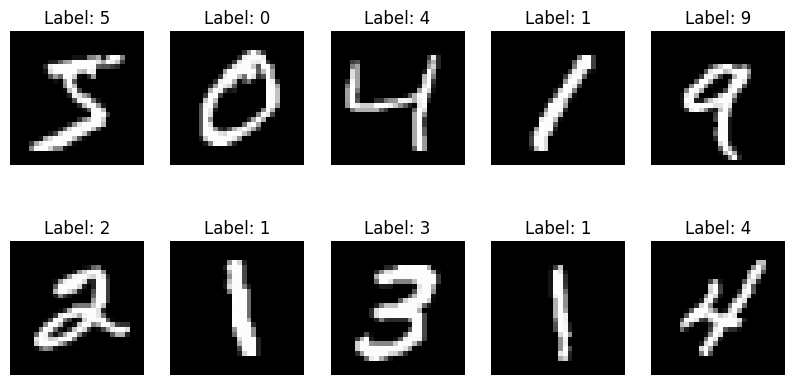

In [8]:
# Step 1: Import necessary libraries and load the dataset
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
import matplotlib.pyplot as plt
import numpy as np

# Load the MNIST dataset
# x_train contains the training images (60,000 images)
# y_train contains the training labels (the correct number for each image)
# x_test contains the testing images (10,000 images)
# y_test contains the testing labels
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Let's see what our data looks like
print(f"Number of training images: {x_train.shape[0]}")
print(f"Image shape: {x_train.shape[1]}x{x_train.shape[2]} pixels")

# Display a few sample images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

In [9]:
# Step 2: Preprocess the data

# Normalize the pixel values from the range [0, 255] to the range [0, 1]
# This helps the model train faster and more stably.
x_train = x_train / 255.0
x_test = x_test / 255.0

# The labels (y_train, y_test) are already numbers from 0 to 9, so we don't need to change them.
print("Data normalized. Sample pixel value after normalization:")
print(x_train[0][10:15, 10:15]) # Print a small patch of the first image

Data normalized. Sample pixel value after normalization:
[[0.00392157 0.60392157 0.99215686 0.35294118 0.        ]
 [0.         0.54509804 0.99215686 0.74509804 0.00784314]
 [0.         0.04313725 0.74509804 0.99215686 0.2745098 ]
 [0.         0.         0.1372549  0.94509804 0.88235294]
 [0.         0.         0.         0.31764706 0.94117647]]


In [10]:
# Step 3: Build the neural network model

model = Sequential([
    # 1. Flatten Layer: Converts each 28x28 image into a 1D array of 784 pixels.
    Flatten(input_shape=(28, 28)),

    # 2. Hidden Layer: A fully connected layer with 128 neurons.
    # 'relu' (Rectified Linear Unit) is a common activation function that helps the model learn non-linear patterns.
    Dense(128, activation='relu'),

    # 3. Output Layer: A fully connected layer with 10 neurons (one for each digit 0-9).
    # 'softmax' activation converts the output scores into probabilities, ensuring they sum to 1.
    # The neuron with the highest probability is the model's prediction.
    Dense(10, activation='softmax')
])

# Print a summary of the model architecture
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Step 4: Compile and train the model

# Compile the model
# 'optimizer' is the algorithm that adjusts the model's weights (e.g., 'adam' is a popular choice).
# 'loss' is the function that measures how wrong the model's predictions are.
# 'metrics' are used to monitor the training process (we want to see the 'accuracy').
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
# We "fit" the model to the training data.
# 'epochs' is the number of times the model will see the entire training dataset.
print("\nStarting training...")
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)
print("Training finished!")


Starting training...
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8706 - loss: 0.4543 - val_accuracy: 0.9683 - val_loss: 0.1174
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9625 - loss: 0.1245 - val_accuracy: 0.9743 - val_loss: 0.0859
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9772 - loss: 0.0789 - val_accuracy: 0.9753 - val_loss: 0.0860
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9828 - loss: 0.0560 - val_accuracy: 0.9767 - val_loss: 0.0760
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9872 - loss: 0.0431 - val_accuracy: 0.9802 - val_loss: 0.0666
Training finished!


In [12]:
# Step 5: Evaluate the model on the test set

print("\nEvaluating model on the test set...")
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_acc*100:.2f}%")


Evaluating model on the test set...
313/313 - 1s - 2ms/step - accuracy: 0.9774 - loss: 0.0734

Test accuracy: 97.74%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


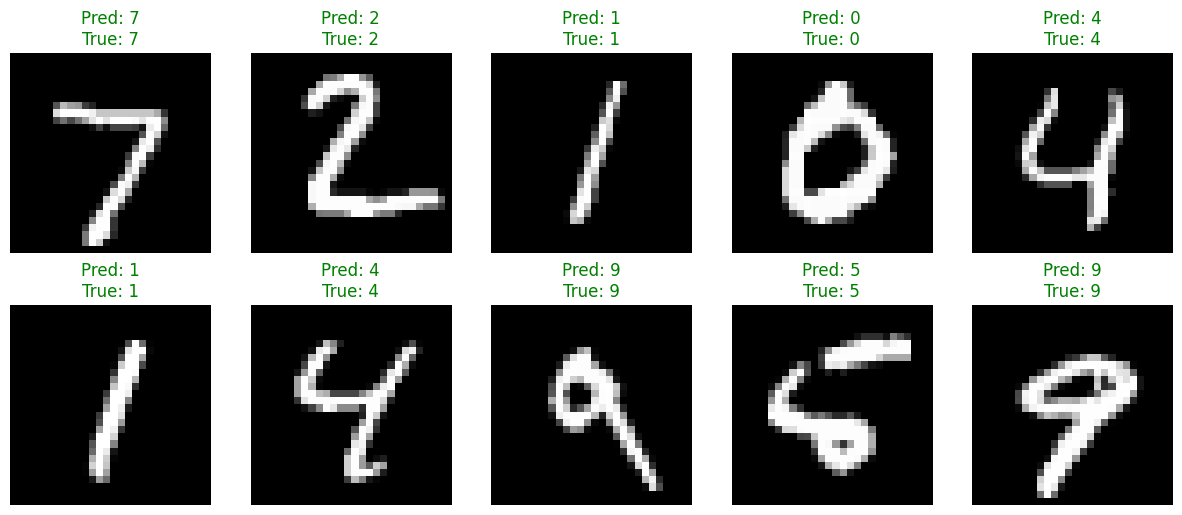

In [14]:
# Step 6: Make predictions on new data

# Get predictions for the first 10 images in the test set
predictions = model.predict(x_test[:10])

# Display the images, their predicted labels, and their true labels
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    # The prediction is the index of the neuron with the highest probability
    predicted_label = np.argmax(predictions[i])
    true_label = y_test[i]

    # Color the title green for correct predictions, red for incorrect
    color = 'green' if predicted_label == true_label else 'red'
    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=color)
    plt.axis('off')
plt.show()